In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
def get_histogram(con, table, column, n_bins=100):

    # Get the full range of the variable
    min_val, max_val = con.execute(f"""
        SELECT MIN({column}), MAX({column})
        FROM {table}
        WHERE {column} IS NOT NULL
          AND isfinite({column})
    """).fetchone()

    bin_width = (max_val - min_val) / n_bins

   # Calculate frequency in each bin
    hist = con.execute(f"""
        SELECT
            LEAST(CAST(FLOOR(({column} - {min_val}) / {bin_width}) AS INTEGER), {n_bins - 1}) AS bin,
            COUNT(*) AS frequency
        FROM {table}
        WHERE {column} IS NOT NULL
          AND isfinite({column})
        GROUP BY bin
        ORDER BY bin
    """).fetchdf()

# Bin centers
    hist["center"] = min_val + (hist["bin"] + 0.5) * bin_width

    return hist, min_val, max_val, bin_width

In [ ]:
TRK_FILE = (r"tracking_table_60min.parquet")

con = duckdb.connect("tracking_analysis.duckdb")
con.execute(
    f"""
    CREATE OR REPLACE VIEW TRACK_TABLE AS
    SELECT *
    FROM read_parquet('{TRK_FILE}', union_by_name = true)
    """
)

all_size_precip = con.execute("""
    SELECT size, min, mean, max
    FROM TRACK_TABLE
    WHERE uid IS NOT NULL
      AND timestamp >= TIMESTAMP '2001-01-01'
      AND size IS NOT NULL
      AND min IS NOT NULL
      AND mean IS NOT NULL
      AND max IS NOT NULL
    ORDER by uid
""").fetchdf()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [4]:
# Variables and their expressions
variables = {
    "Effective Radius": "SQRT(size * 100.0 / PI())",
    "Min Rain Rate": '"min"',
    "Mean Rain Rate": '"mean"',
    "Max Rain Rate": '"max"'
}
histograms = {}

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

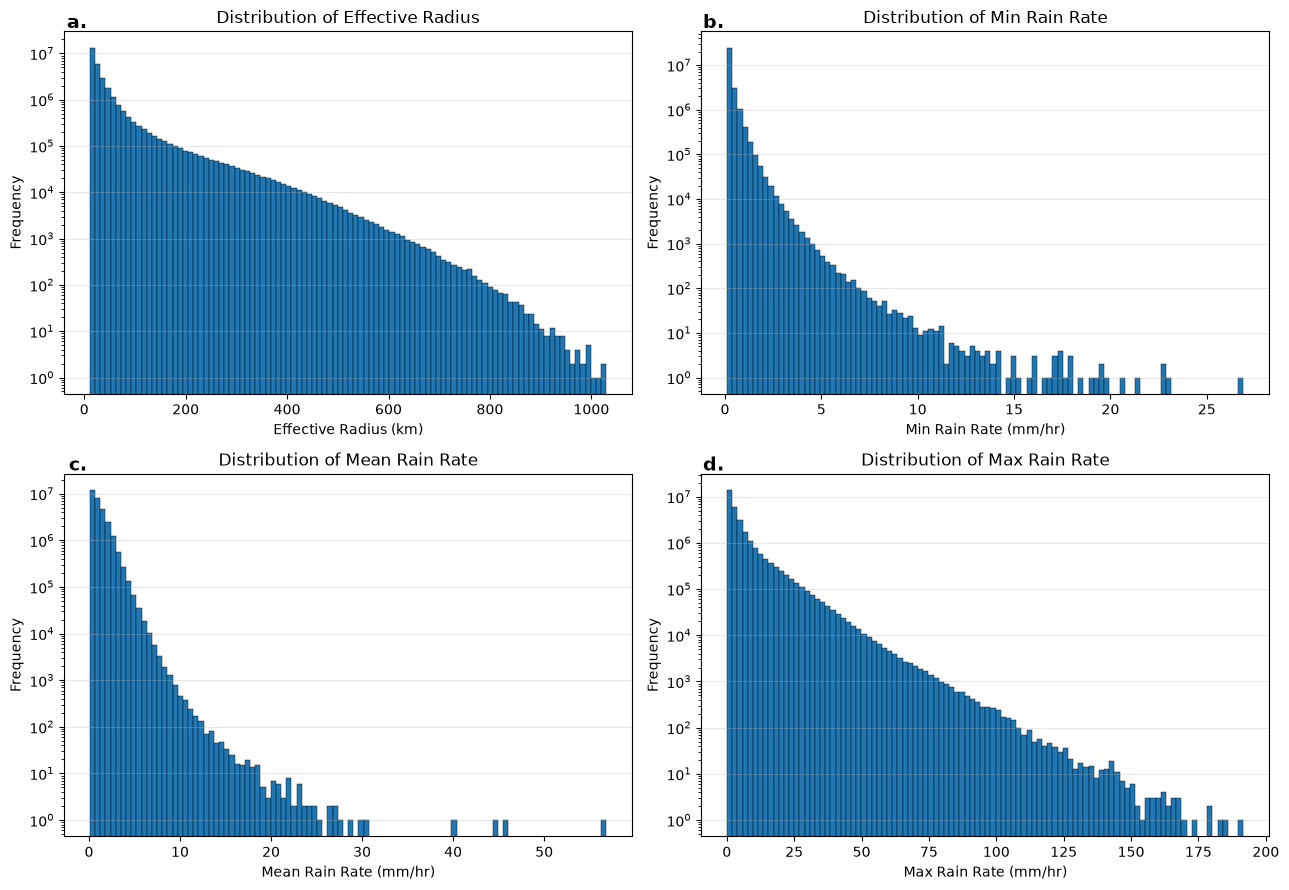

In [5]:
for name, expression in variables.items():
    histograms[name] = get_histogram(con, "TRACK_TABLE", expression, n_bins=100)

# Plot distributions
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for ax, (name, _) in zip(axes, variables.items()):
    hist, min_val, max_val, bin_width = histograms[name]
    ax.bar(hist["center"], hist["frequency"], width=bin_width, edgecolor="black", linewidth=0.3)
    ax.set_title(f"Distribution of {name}")

    if name.lower() == "effective radius":
        ax.set_xlabel("Effective Radius (km)")
    else:
        ax.set_xlabel(name + " (mm/hr)")
    
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.3)
    ax.set_yscale("log")
    ax.text(0.04, 1.05, f"{chr(97 + list(variables.keys()).index(name))}.", transform=ax.transAxes, fontsize=14, fontweight="bold", ha="right", va="top")

plt.tight_layout()
plt.show()